In [27]:
import pandas as pd   
import numpy as np    
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

import seaborn as sns
import matplotlib.pyplot as plt


### 데이터 불러오기

In [28]:
df = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
submission = pd.read_csv("submission_example.csv")

### 데이터 설명

| 변수명           | 데이터타입 | 설명                        | 범주 값 또는 예시                                                                                                                         |
| ------------- | ----- | ------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| **age**       | 수치형   | 나이                        | -                                                                                                                                  |
| **job**       | 범주형   | 직업                        | admin, unknown, unemployed, management, housemaid, entrepreneur, student, blue-collar, self-employed, retired, technician, service |
| **marital**   | 범주형   | 결혼상태                      | married, divorced,single (사별해도 divorced로 포함)                                                                                                          |
| **education** | 범주형   | 학력                        | unknown, secondary, primary, tertiary                                                                                              |
| **default**   | 범주형   | 신용 채무 불이행 여부              | yes, no                                                                                                                            |
| **balance**   | 수치형   | 연평균 잔액 (단위: 유로)           | -                                                                                                                                  |
| **housing**   | 범주형   | 주택 대출 여부                  | yes, no                                                                                                                            |
| **loan**      | 범주형   | 개인 대출 여부                  | yes, no                                                                                                                            |
| **contact**   | 범주형   | 최근 연락 수단                  | unknown, telephone, cellular                                                                                                       |
| **day**       | 수치형   | 최근 연락 날짜                  | 1 \~ 31                                                                                                                            |
| **month**     | 범주형   | 최근 연락한 달                  | jan, feb, mar, ..., dec                                                                                                            |
| **duration**  | 수치형   | 최근 통화 시간 (초)              | -                                                                                                                                  |
| **campaign**  | 수치형   | 이번 캠페인 중 고객에게 연락한 횟수      | -                                                                                                                                  |
| **pdays**     | 수치형   | 이전 캠페인 이후 경과일 (-1은 연락 없음) | -                                                                                                                                  |
| **previous**  | 수치형   | 이전 캠페인에서 고객에게 연락한 횟수      | -                                                                                                                                  |
| **poutcome**  | 범주형   | 이전 캠페인 결과                 | unknown, other, failure, success                                                                                                   |
| **label**     | 범주형   | 정기예금 가입 여부 (타겟 변수)        | 1 = 가입, 0 = 미가입                                                                                                                    |


## EDA

### 결측치 확인

In [29]:
df.isnull().sum()

ID           0
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
label        0
dtype: int64

#### Target

### train_test data 나누기

In [52]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['label' , 'ID'])  
y = df['label']               

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## PipeLine

#### 범주형 변수 pipeline 작성

- one hot encoder : binary 변수 일때 사용
    - 'default', 'loan', 'housing' (Y/N) , 'marital', 'contact' (유의미한 most_frequent에 해당하는 범주가 있음)
- target encder : 범주와 타겟간의 연관성이 명확할 때 사용
    - job, poutcome,
- ordinal encoder : 순서 있는 범주에 사용
    - education

In [53]:
#!pip install category_encoders 

In [54]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from category_encoders import TargetEncoder
from sklearn.preprocessing import FunctionTransformer
import numpy as np

# 월 -> 숫자 변환
month_map = {'jan':1, 'feb':2, 'mar':3, 'apr':4, 'may':5, 'jun':6,
             'jul':7, 'aug':8, 'sep':9, 'oct':10, 'nov':11, 'dec':12}

# custom function for mapping
def month_to_num(X):
    return X.replace(month_map)

month_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('mapper', FunctionTransformer(month_to_num)),
])

education_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(
        categories=[['primary', 'secondary', 'tertiary']],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

job_target_encoder = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target', TargetEncoder())
])

poutcome_target_encoder = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target', TargetEncoder())
])

binary_col = ['default', 'loan', 'housing']
binary_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore'))
])

other_col = ['marital', 'contact']
other_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
])


In [55]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer
from sklearn.compose import ColumnTransformer

#pdays 에 대해서는 -1 (연락없음)과 같은 특수 카테고리기 때문에 -1 변수를 999로 할당함.
pdays_transformer = Pipeline([
    ('minus1_to_nan', FunctionTransformer(lambda x: x.replace(-1, np.nan))),
    ('imputer', SimpleImputer(strategy='constant', fill_value=999)),
    ('scaler', PowerTransformer(method='yeo-johnson'))
])

num_pipeline = ColumnTransformer(transformers=[
    ('age', StandardScaler(), ['age']),
    ('balance', PowerTransformer(method='yeo-johnson'), ['balance']),
    ('duration', PowerTransformer(method='yeo-johnson'), ['duration']),
    ('campaign', RobustScaler(), ['campaign']),
    ('previous', PowerTransformer(method='yeo-johnson'), ['previous']),
    ('pdays', pdays_transformer, ['pdays'])
], remainder='drop')

In [67]:
cat_preprocessor = ColumnTransformer(transformers=[
    ('month', month_transformer, ['month']),
    ('education', education_transformer, ['education']),
    ('job', job_target_encoder, ['job']),
    ('poutcome', poutcome_target_encoder, ['poutcome']),
    ('binary', binary_transformer, binary_col),
    ('other', other_transformer, other_col)
])


In [68]:
model_pipeline = ColumnTransformer(transformers=[
    ('cat', cat_preprocessor, cat_col),
    ('num', num_pipeline, [col for col in num_col if col != 'day']) #day 변수 제외
])

model_pipeline.set_output(transform='pandas')

ColumnTransformer(transformers=[('cat',
                                 ColumnTransformer(transformers=[('month',
                                                                  Pipeline(steps=[('imputer',
                                                                                   SimpleImputer(strategy='most_frequent')),
                                                                                  ('mapper',
                                                                                   FunctionTransformer(func=<function month_to_num at 0x32c082700>))]),
                                                                  ['month']),
                                                                 ('education',
                                                                  Pipeline(steps=[('imputer',
                                                                                   SimpleImputer(strategy='most_frequent')),
                                                                                  ('ordinal',
                                                                                   OrdinalEncoder(categorie...
                                                                 ('campaign',
                                                                  RobustScaler(),
                                                                  ['campaign']),
                                                                 ('previous',
                                                                  PowerTransformer(),
                                                                  ['previous']),
                                                                 ('pdays',
                                                                  Pipeline(steps=[('minus1_to_nan',
                                                                                   FunctionTransformer(func=<function <lambda> at 0x32c082ca0>)),
                                                                                  ('imputer',
                                                                                   SimpleImputer(fill_value=999,
                                                                                                 strategy='constant')),
                                                                                  ('scaler',
                                                                                   PowerTransformer())]),
                                                                  ['pdays'])]),
                                 ['age', 'balance', 'duration', 'campaign',
                                  'pdays', 'previous'])])

## Modeling

In [70]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
import xgboost as xgb
import lightgbm as lgb

In [71]:
models = {
    "RandomForest": RandomForestClassifier(random_state=42),
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(probability=True),
    "XGBoost": xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    "LightGBM": lgb.LGBMClassifier(random_state=42)
}

In [72]:
from sklearn.metrics import f1_score

results = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', model_pipeline),
        ('classifier', model)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_val)
    f1 = f1_score(y_val, y_pred)
    results[name] = f1

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_29762/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return X.replace(month_map)
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_29762/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return X.replace(month_map)
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_29762/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explici

[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000686 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 751
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116996 -> initscore=-2.021185
[LightGBM] [Info] Start training from score -2.021185


/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_29762/3913398071.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return X.replace(month_map)


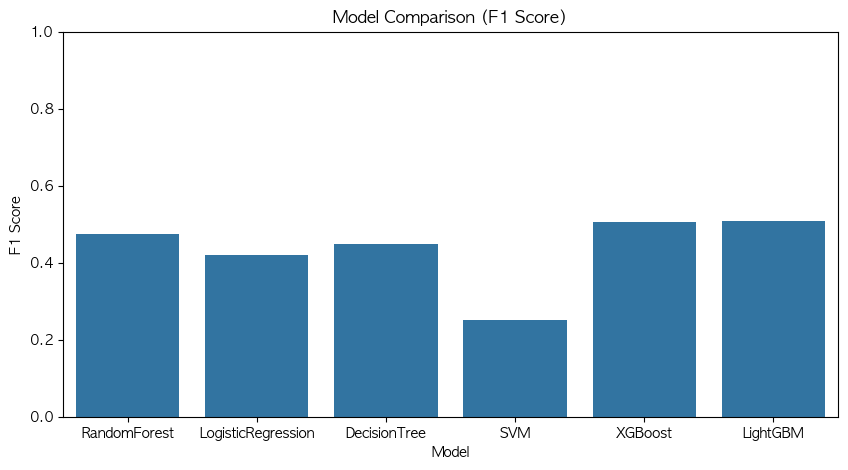

In [73]:
result_df = pd.DataFrame(list(results.items()), columns=['Model', 'F1 Score'])
plt.figure(figsize=(10,5))
sns.barplot(x='Model', y='F1 Score', data=result_df)
plt.title('Model Comparison (F1 Score)')
plt.ylim(0, 1)
plt.show()

### Optuna

In [62]:
# optimizing 10 번 진행

- RandomForest, XGBoost, LogisticRegression 하이퍼파라미터 튜닝
- StackingClassifier로 세 모델 앙상블 구성
- predict_proba()로 확률값 추출
- Threshold를 0.3 ~ 0.7 사이에서 변화시켜 F1-score를 최적화
- 최적 threshold에서의 F1-score를 Optuna의 objective값으로 반환

In [63]:
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
import numpy as np
from sklearn.metrics import f1_score

In [64]:
def objective(trial):
    rf = RandomForestClassifier(
        n_estimators=trial.suggest_int("rf_n_estimators", 50, 200),
        max_depth=trial.suggest_int("rf_max_depth", 3, 15),
        class_weight="balanced",
        random_state=42
    )
    xgb = XGBClassifier(
        n_estimators=trial.suggest_int("xgb_n_estimators", 50, 200),
        max_depth=trial.suggest_int("xgb_max_depth", 3, 15),
        learning_rate=trial.suggest_float("xgb_lr", 0.01, 0.3),
        use_label_encoder=False,
        eval_metric="logloss",
        random_state=42,
        scale_pos_weight=trial.suggest_float("xgb_spw", 1.0, 5.0),
        early_stopping_rounds=20 #과적합 방지를 위해 조기종료 포함
    )
    lr = LogisticRegression(
        C=trial.suggest_float("lr_C", 0.01, 10.0),
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )

    clf = StackingClassifier(
        estimators=[("rf", rf), ("xgb", xgb), ("lr", lr)],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5,
        passthrough=True  # 원본 특성도 최종 모델에 전달
    )

    clf.fit(X_train, y_train)
    probs = clf.predict_proba(X_valid)[:, 1]

    # Threshold tuning
    thresholds = np.linspace(0.3, 0.7, 21)
    f1_scores = [f1_score(y_valid, (probs >= t).astype(int)) for t in thresholds]
    
    return max(f1_scores)

import optuna

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

print("Best F1-score:", study.best_value)
print("Best params:", study.best_params)

[I 2025-05-20 18:26:14,517] A new study created in memory with name: no-name-943acea7-7713-4ef3-a09b-21588560e8c3
[W 2025-05-20 18:26:14,527] Trial 0 failed with parameters: {'rf_n_estimators': 164, 'rf_max_depth': 11, 'xgb_n_estimators': 194, 'xgb_max_depth': 15, 'xgb_lr': 0.021397070232717925, 'xgb_spw': 1.2689727071748464, 'lr_C': 8.541579631150062} because of the following error: ValueError("could not convert string to float: 'management'").
Traceback (most recent call last):
  File "/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/optuna/study/_optimize.py", line 197, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_29762/2351319509.py", line 32, in objective
    clf.fit(X_train, y_train)
  File "/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py", line 63, in inner_f
    return f(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^
  File "/opt/a

ValueError: could not convert string to float: 'management'

In [65]:
best_params = study.best_params

final_rf = RandomForestClassifier(
    n_estimators=best_params["rf_n_estimators"],
    max_depth=best_params["rf_max_depth"],
    class_weight="balanced",
    random_state=42
)
final_xgb = XGBClassifier(
    n_estimators=best_params["xgb_n_estimators"],
    max_depth=best_params["xgb_max_depth"],
    learning_rate=best_params["xgb_lr"],
    scale_pos_weight=best_params["xgb_spw"],
    use_label_encoder=False,
    eval_metric="logloss",
    random_state=42
)
final_lr = LogisticRegression(
    C=best_params["lr_C"],
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

final_stack = StackingClassifier(
    estimators=[("rf", final_rf), ("xgb", final_xgb), ("lr", final_lr)],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    passthrough=True
)

final_stack.fit(X_train, y_train)

ValueError: No trials are completed yet.

In [ ]:
# Threshold 다시 튜닝해서 적용
final_probs = final_stack.predict_proba(X_valid)[:, 1]
thresholds = np.linspace(0.3, 0.7, 21)
f1s = [f1_score(y_valid, (final_probs >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[np.argmax(f1s)]
print(f"Best threshold: {best_threshold:.2f}, F1: {np.max(f1s):.4f}")